# Where should Blinkit open its next dark stores in Indore?

Blinkit operated **2,443 dark stores** as of June 2026 and continues to add more every quarter, at a
long-run capital cost of roughly **₹2.5 crore per store** including warehousing. At that scale, deciding
where to put the next store is not a logistics question — it is a capital allocation question, and it is
made under three hard limits at once: a fixed budget, a delivery radius the ten-minute promise cannot
survive breaking, and a ceiling on how many orders a single store can physically pick and pack in a day.

This notebook models that decision for one city as a **capacitated facility location problem**, solved as a
mixed-integer linear program. It chooses which sites to open *and* how to route each locality's demand
across them, then measures the result against the greedy heuristic most teams would reach for informally.

The comparison is the point. An optimizer without a benchmark produces a number nobody can judge.

---

## What is real, and what I made up

Everything in this notebook is one of two things, and the distinction is maintained deliberately
throughout. Mixing them is how a synthetic-data project stops being credible.

### Disclosed facts

These come from Eternal's public reporting and are used to calibrate the model. They are not invented,
and nothing here extends them beyond what was actually stated.

| Fact | Value | Source |
|---|---|---|
| Blinkit store count | 2,443 | Eternal Q1 FY27 (June 2026) |
| Capex per store, incl. warehousing | ~₹2.5 crore | Eternal, long-run assumption |
| Steady-state NOV per store per day | ~₹11 lakh | Eternal, steady-state target |
| Network working capital | ~12 days | Eternal |
| Target pre-tax ROCE | ~41.7% | Eternal, under the above assumptions |
| Network footprint | ~19 million sq ft across 300+ cities | Eternal |
| Inventory and spoilage loss | ~1.8% of NOV, described as "fairly asymptotic" | Eternal |
| Average delivery distance (peer) | ~1.7–1.8 km, FY26 | Zepto disclosure |

### Synthetic assumptions

Everything below was invented for this project. **No real Blinkit order, rent, store-location or dispatch
data was used, and none is available publicly at this granularity.**

| Assumption | Value | Why this value |
|---|---|---|
| City | Indore | Tier-2, thin quick-commerce presence, so expansion is a genuine question |
| Localities | 35, with real names and approximate coordinates | Enough spatial structure to matter, small enough to solve in seconds |
| Demand history | 90 days, 1 Sep – 29 Nov 2025 | Contains Diwali (20 Oct 2025), so the festive peak is real rather than arbitrary |
| Candidate sites | 50 | — |
| Existing stores | 6 | Makes the decision incremental, matching the real situation |
| Average order value | ~₹560 blended, by income tier | **Assumed.** Drives the capacity derivation below |
| Store capacity | ~1,200–2,400 orders/day | **Derived**, see below |
| Delivery radius | 2.5 km | Assumed, anchored on the disclosed ~1.7–1.8 km peer average |
| Budget | ₹20 crore | Assumed — roughly eight stores at the disclosed capex |

### One derivation worth stating explicitly

Store capacity is not disclosed anywhere. It is derived:

```
₹11,00,000 NOV per store per day  ÷  ~₹600 average order value  ≈  1,800 orders per store per day
```

The ₹11 lakh is theirs. The ₹600 is mine. **So 1,800 is neither a fact nor a measurement — it is an
estimate that inherits the weakest link in its chain**, and it moves a great deal with the assumption:

| If AOV is | Capacity works out to |
|---|---|
| ₹500 | ~2,200 orders/day |
| ₹600 | ~1,800 orders/day |
| ₹700 | ~1,570 orders/day |

Site capacities in the data are therefore spread across roughly 1,200–2,400 rather than fixed at a
spuriously precise 1,800.

---

## Setup

The project runs on MySQL 8 if `DATABASE_URL` is set, and falls back to a local SQLite file otherwise, so
it works on a clean machine with no database server. Run `python generate_data.py` first if you have not.

In [1]:
import sys
sys.path.insert(0, "..") if "src" not in sys.modules else None

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sqlalchemy import text

from src.db import get_engine, load_query, backend_name, describe_connection, is_weekend_expr
from src.geo import build_facilities, distance_matrix, feasible_mask, coverage_report, DEFAULT_RADIUS_KM
from src.baseline import greedy_network
from src.optimizer import optimize_network, sensitivity_sweep, scenario_analysis, relaxation_gap
from src.evaluate import compare
from src import plots

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)
plt.rcParams["figure.dpi"] = 110

BUDGET = 20e7          # Rs 20 crore
RADIUS_KM = DEFAULT_RADIUS_KM

engine = get_engine()
print(f"backend: {backend_name(engine)}")
print(f"target : {describe_connection(engine)}")   # password is stripped by SQLAlchemy

backend: SQLite
target : sqlite:///data/blinkit_sim.db


---

## Exploring the data in SQL

The queries below run against the database rather than against pandas. That is deliberate: the questions
being asked — ranking within groups, finding localities with no nearby store, smoothing a daily series —
are questions SQL answers well, and doing them in SQL keeps the heavy aggregation next to the data
instead of pulling 3,150 rows into memory to do arithmetic on them.

Each query lives in its own file under `sql/queries/` so it can be opened in a SQL editor, and each cell
prints the query before running it.

### 1. Demand by locality

Straightforward aggregation, but note the revenue column: it multiplies each day's order count by *that
day's* average basket before summing. Summing orders and multiplying by an overall average instead would
weight quiet days equally with busy ones, which understates exactly the days that generate the most
revenue.

In [2]:
q1 = load_query("01_demand_by_locality.sql")
print(q1.split("\n\n")[-1])          # the SQL, without the explanatory header

demand_by_locality = pd.read_sql(text(q1), engine)
demand_by_locality.head(10)

SELECT
    l.locality_id,
    l.locality_name,
    l.avg_household_income_tier,
    l.population_density,
    COUNT(*)                                        AS days_observed,
    SUM(d.order_count)                              AS total_orders,
    ROUND(AVG(d.order_count), 1)                    AS avg_orders_per_day,
    ROUND(AVG(d.avg_order_value), 2)                AS avg_order_value,
    ROUND(SUM(d.order_count * d.avg_order_value), 2) AS total_revenue
FROM demand AS d
JOIN localities AS l
    ON l.locality_id = d.locality_id
GROUP BY
    l.locality_id,
    l.locality_name,
    l.avg_household_income_tier,
    l.population_density
ORDER BY
    avg_orders_per_day DESC;



,locality_id,locality_name,avg_household_income_tier,population_density,days_observed,total_orders,avg_orders_per_day,avg_order_value,total_revenue
0,12,Palasia,high,25492.86,90,181043,2011.6,723.88,1.318891e+08
1,10,New Palasia,high,25685.21,90,180828,2009.2,726.50,1.318298e+08
2,25,LIG Colony,high,22117.81,90,160137,1779.3,727.20,1.169232e+08
3,11,Old Palasia,high,21537.63,90,156903,1743.4,724.05,1.140544e+08
4,24,MIG Colony,high,21291.66,90,155062,1722.9,721.71,1.122481e+08
5,2,Sarafa Bazar,mid,32064.45,90,150184,1668.7,560.82,8.464707e+07
6,14,Saket Nagar,high,19338.56,90,143280,1592.0,721.41,1.037868e+08
7,6,Malviya Nagar,mid,30100.66,90,142360,1581.8,559.46,8.012554e+07
8,4,Chhoti Gwaltoli,mid,29637.65,90,139963,1555.1,565.15,7.944909e+07
9,5,Sanyogitaganj,mid,28436.77,90,135782,1508.7,562.52,7.682595e+07


### 2. Where is demand going unserved?

The business question, asked directly: which high-demand localities have no store within the delivery
radius? Distance is computed in SQL with the haversine formula written longhand, since there is no
geography type in play.

Two details worth noting. The formula uses the `ASIN` form rather than the shorter spherical law of
cosines — for points a couple of kilometres apart the cosine of the subtended angle rounds to just above
1.0 in floating point, which takes `ACOS` outside its domain. And the exclusion uses `NOT EXISTS` rather
than a `LEFT JOIN` with a null check, which lets the engine stop scanning as soon as it finds one nearby
store instead of building every locality-store pair and discarding most of them.

In [3]:
q2 = load_query("02_underserved_localities.sql")
print(q2.split("\n\n")[-1])

with engine.connect() as conn:
    underserved = pd.read_sql(text(q2), conn, params={"radius_km": RADIUS_KM})
underserved

WITH locality_demand AS (
    SELECT
        d.locality_id,
        AVG(d.order_count) AS avg_orders_per_day
    FROM demand AS d
    GROUP BY d.locality_id
)
SELECT
    l.locality_id,
    l.locality_name,
    l.avg_household_income_tier,
    ROUND(ld.avg_orders_per_day, 1) AS avg_orders_per_day,
    ROUND(l.population_density, 0)  AS population_density
FROM localities AS l
JOIN locality_demand AS ld
    ON ld.locality_id = l.locality_id
WHERE NOT EXISTS (
    SELECT 1
    FROM existing_stores AS s
    WHERE 2 * 6371.0 * ASIN(
              SQRT(
                  POWER(SIN((RADIANS(s.latitude) - RADIANS(l.latitude)) / 2), 2)
                  + COS(RADIANS(l.latitude)) * COS(RADIANS(s.latitude))
                  * POWER(SIN((RADIANS(s.longitude) - RADIANS(l.longitude)) / 2), 2)
              )
          ) <= :radius_km
)
ORDER BY ld.avg_orders_per_day DESC
LIMIT 10;



,locality_id,locality_name,avg_household_income_tier,avg_orders_per_day,population_density
0,27,Dewas Naka,high,745.3,7578.0
1,29,Bhawarkuan,low,669.2,14862.0
2,17,Bengali Square,mid,579.9,8893.0
3,26,Sukhliya,mid,503.0,7427.0
4,19,Bicholi Mardana,mid,386.8,5393.0
5,20,Nipania,mid,378.0,5295.0
6,32,Annapurna,low,354.3,6862.0
7,18,Kanadia Road,low,342.1,6636.0
8,30,Musakhedi,low,305.1,5699.0
9,34,Silicon City,low,250.9,4551.0


### 3. Ranking within income tier

A window function rather than a `GROUP BY`, because the question is about each locality's position
*relative to its peers* — and a `GROUP BY` would collapse the localities away entirely.

The metric being ranked matters as much as the ranking. Raw order volume would simply rediscover that
large localities are large; dividing demand by population density measures how hard a neighbourhood
punches for its size, which is the more interesting question.

In [4]:
q3 = load_query("03_rank_within_income_tier.sql")
print(q3.split("\n\n")[-1])

tier_ranks = pd.read_sql(text(q3), engine)
tier_ranks[tier_ranks["rank_in_tier"] <= 3]

    -- A second window over the same partition, this time an aggregate rather
    -- than a ranking. Because it keeps every row, each locality can be compared
    -- against its own tier's average on the same line -- something GROUP BY
    -- would need a self-join to achieve.
    ROUND(
        AVG(avg_orders_per_day) OVER (PARTITION BY avg_household_income_tier),
        1
    ) AS tier_avg_orders_per_day
FROM locality_stats
ORDER BY
    avg_household_income_tier,
    rank_in_tier;



,locality_name,avg_household_income_tier,avg_orders_per_day,population_density,orders_per_1k_density,rank_in_tier,tier_avg_orders_per_day
0,Dewas Naka,high,745.3,7578.0,98.35,1,1542.2
1,Scheme 78,high,1100.3,12313.0,89.36,2,1542.2
2,Scheme 54,high,1330.1,15521.0,85.70,3,1542.2
10,Rau,low,126.3,1924.0,65.66,1,507.3
11,Sudama Nagar,low,191.7,3333.0,57.50,2,507.3
12,Silicon City,low,250.9,4551.0,55.13,3,507.3
22,Bicholi Mardana,mid,386.8,5393.0,71.72,1,1034.2
23,Nipania,mid,378.0,5295.0,71.38,2,1034.2
24,Sukhliya,mid,503.0,7427.0,67.73,3,1034.2


### 4. Weekday against weekend

Conditional aggregation: a `CASE WHEN` inside `AVG()` yields a value on the days of interest and `NULL`
elsewhere, and because aggregates skip nulls, one pass over the table produces both averages. Using
`ELSE 0` instead would drag both averages toward zero and silently give the wrong answer.

This is the one place MySQL and SQLite genuinely disagree — `DAYOFWEEK()` against `strftime('%w')` — so
the expression is substituted at runtime.

In [5]:
q4 = load_query("04_weekday_vs_weekend.sql").format(
    is_weekend=is_weekend_expr(engine, "d.order_date")
)
print(q4.split("\n\n")[-1])

weekend = pd.read_sql(text(q4), engine)
print(f"weekday days: {weekend['weekday_days'].iloc[0]}, weekend days: {weekend['weekend_days'].iloc[0]}"
      f"  (total {weekend['weekday_days'].iloc[0] + weekend['weekend_days'].iloc[0]})")
weekend.head(8)

    -- Counting rows that satisfy a condition, same CASE WHEN idea applied to
    -- SUM instead of AVG. Serves as a sanity check that the day-of-week logic
    -- actually split the data the way it was supposed to.
    SUM(CASE WHEN (CAST(strftime('%w', d.order_date) AS INTEGER) + 1) IN (1, 7) THEN 1 ELSE 0 END) AS weekend_days,
    SUM(CASE WHEN (CAST(strftime('%w', d.order_date) AS INTEGER) + 1) IN (1, 7) THEN 0 ELSE 1 END) AS weekday_days
FROM demand AS d
JOIN localities AS l
    ON l.locality_id = d.locality_id
GROUP BY
    l.locality_id,
    l.locality_name,
    l.avg_household_income_tier
ORDER BY
    weekend_uplift_pct DESC;

weekday days: 65, weekend days: 25  (total 90)


,locality_name,avg_household_income_tier,avg_weekday_orders,avg_weekend_orders,weekend_uplift_pct,weekend_days,weekday_days
0,Sudama Nagar,low,177.1,229.4,29.5,25,65
1,Annapurna,low,328.7,420.8,28.0,25,65
2,Sanyogitaganj,mid,1400.5,1790.0,27.8,25,65
3,Vijay Nagar,high,1288.5,1645.2,27.7,25,65
4,Old Palasia,high,1619.8,2064.6,27.5,25,65
5,Bengali Square,mid,538.7,686.9,27.5,25,65
6,Dewas Naka,high,692.6,882.2,27.4,25,65
7,Pipliyahana,low,335.0,426.5,27.3,25,65


### 5. Smoothing demand for the model

This query produces the demand vector the optimizer consumes, which makes it the most consequential one
here — an error propagates into every downstream result.

Daily counts are Poisson, so variance equals mean and a locality averaging 400 orders swings between
roughly 360 and 440 on chance alone. Siting a store on one day's reading would be fitting to noise. The
seven-day window is not arbitrary: it is exactly one period of the weekly cycle, so averaging over it
cancels the weekday-weekend effect rather than letting it leak through.

The frame clause `ROWS BETWEEN 6 PRECEDING AND CURRENT ROW` is what makes this rolling. Without it, a
window function with an `ORDER BY` defaults to a *cumulative* total from the start of the partition —
which looks similar and is not the same thing.

In [6]:
q5 = load_query("05_rolling_demand_cte.sql")
print(q5.split("\n\n")[-1])

localities = pd.read_sql(text(q5), engine)
print(f"{len(localities)} localities, {localities['smoothed_orders_per_day'].sum():,.0f} orders/day citywide")
localities.head(8)

SELECT
    l.locality_id,
    l.locality_name,
    l.latitude,
    l.longitude,
    l.avg_household_income_tier,
    l.population_density,
    ROUND(AVG(s.rolling_7d_orders), 1) AS smoothed_orders_per_day,
    ROUND(AVG(s.avg_order_value), 2)   AS avg_order_value,
    COUNT(*)                           AS days_used
FROM settled AS s
JOIN localities AS l
    ON l.locality_id = s.locality_id
GROUP BY
    l.locality_id,
    l.locality_name,
    l.latitude,
    l.longitude,
    l.avg_household_income_tier,
    l.population_density
ORDER BY
    smoothed_orders_per_day DESC;

35 localities, 35,120 orders/day citywide


,locality_id,locality_name,latitude,longitude,avg_household_income_tier,population_density,smoothed_orders_per_day,avg_order_value,days_used
0,12,Palasia,22.7244,75.8839,high,25492.86,2021.4,724.96,84
1,10,New Palasia,22.7266,75.8812,high,25685.21,2018.4,728.09,84
2,25,LIG Colony,22.7370,75.8814,high,22117.81,1786.7,726.50,84
3,11,Old Palasia,22.7221,75.8865,high,21537.63,1752.4,724.04,84
4,24,MIG Colony,22.7398,75.8875,high,21291.66,1730.9,720.70,84
5,2,Sarafa Bazar,22.7161,75.8562,mid,32064.45,1678.1,560.04,84
6,14,Saket Nagar,22.7255,75.8950,high,19338.56,1599.9,722.48,84
7,6,Malviya Nagar,22.7200,75.8700,mid,30100.66,1588.7,558.98,84


---

## Geometry

Distances use the haversine formula, not Pythagoras on latitude and longitude. A degree of latitude is
about 111 km everywhere, but a degree of longitude is 111 km × cos(latitude) — roughly 0.92 of that at
Indore. Treating them as interchangeable overstates east-west distance by about 8%, which against a
2.5 km radius is a ~200 m error on the boundary: enough to change which sites can serve which localities,
and therefore enough to change the answer.

The radius is applied as a **mask** rather than as a constraint inside the model. A pair outside the
radius has a known answer — zero — so rather than creating a variable and then constraining it to zero,
the variable is never created. That cuts the assignment variables by about three quarters, and since the
cost of a mixed-integer program is the size of its search tree, that is a meaningful saving.

In [7]:
candidate_sites = pd.read_sql("SELECT * FROM candidate_sites", engine)
existing_stores = pd.read_sql("SELECT * FROM existing_stores", engine)

facilities = build_facilities(candidate_sites, existing_stores)
distances = distance_matrix(localities, facilities)
mask = feasible_mask(distances, RADIUS_KM)
demand = localities["smoothed_orders_per_day"].to_numpy(dtype=float)

print(f"facilities      : {len(facilities)}  ({facilities['is_existing'].sum()} existing, "
      f"{(~facilities['is_existing']).sum()} candidates)")
print(f"feasible pairs  : {mask.sum():,} of {mask.size:,}  ({100 * mask.sum() / mask.size:.1f}%)")
print(f"total demand    : {demand.sum():,.0f} orders/day")

reach = coverage_report(localities, distances, RADIUS_KM)
print(f"unreachable     : {(reach['reachable_facilities'] == 0).sum()} localities")
reach.nsmallest(5, "reachable_facilities")

facilities      : 56  (6 existing, 50 candidates)
feasible pairs  : 500 of 1,960  (25.5%)
total demand    : 35,120 orders/day
unreachable     : 0 localities


,locality_id,locality_name,reachable_facilities,nearest_facility_km
34,35,Rau,1,0.84
27,20,Nipania,2,0.50
26,19,Bicholi Mardana,3,0.53
32,34,Silicon City,3,0.72
33,33,Sudama Nagar,3,0.89


---

## The baseline: a greedy heuristic

Before optimizing anything, it is worth building the thing a competent team would actually do. Open the
site that covers the most currently-unserved demand, then repeat until the money runs out.

This baseline is deliberately **not** crippled. It respects the budget, the capacity ceilings, the
delivery radius and the incumbent network — every constraint the optimizer respects. Beating a weakened
baseline would prove nothing, and it is the first thing a sceptical reader should check.

In [8]:
greedy = greedy_network(localities, facilities, distances, mask, demand,
                        budget=BUDGET, verbose=True)
greedy.summary()

start: 6 existing stores, 10,707/35,120 orders served (30.5%)
  open   S15  capex Rs 3.50 cr  +2,400 orders  budget left Rs 16.50 cr


  open   S36  capex Rs 3.07 cr  +2,348 orders  budget left Rs 13.43 cr
  open   S40  capex Rs 3.05 cr  +2,318 orders  budget left Rs 10.38 cr
  open   S34  capex Rs 3.42 cr  +2,260 orders  budget left Rs 6.97 cr
  open   S33  capex Rs 3.09 cr  +2,198 orders  budget left Rs 3.88 cr
  open   S21  capex Rs 2.84 cr  +2,168 orders  budget left Rs 1.04 cr


{'method': 'greedy',
 'status': 'ok',
 'new_stores': 6,
 'capex_cr': 18.96,
 'demand_served': 24399.0,
 'coverage_pct': 69.5,
 'avg_delivery_km': 0.714,
 'capacity_util_pct': 100.0,
 'solve_seconds': 0.05}

Look at what it bought. Greedy consistently picks the **most expensive, highest-capacity** sites, because
each one individually adds the most demand — and then strands the remainder of the budget, which is too
small to buy anything else.

This is the knapsack trap. A budget of ₹5 crore against sites costing ₹3.0 cr (covering 2,000 orders),
₹2.5 cr (1,800) and ₹2.5 cr (1,700) illustrates it in miniature: greedy takes the first, cannot afford
either of the others, and serves 2,000. Taking the second and third together costs exactly ₹5 crore and
serves 3,500 — 75% more for the same money. Greedy never considers the pair, because it only ever
evaluates one site at a time and commits irrevocably to each choice.

That exact case is encoded as a test in `tests/test_toy.py`.

In [9]:
print(f"budget stranded: Rs {greedy.notes['budget_unused'] / 1e7:.2f} cr of Rs {BUDGET / 1e7:.0f} cr")
greedy.opened_sites()

budget stranded: Rs 1.04 cr of Rs 20 cr


,facility_key,locality_id,latitude,longitude,capacity,capex_cr,orders_served,utilisation_pct
0,S15,11,22.712698,75.883147,2400.0,3.50,2400.0,100.0
1,S21,14,22.722286,75.895802,2168.0,2.84,2168.0,100.0
2,S33,23,22.759765,75.882127,2198.0,3.09,2198.0,100.0
3,S34,24,22.737839,75.879562,2260.0,3.42,2260.0,100.0
4,S36,25,22.747371,75.882084,2348.0,3.07,2348.0,100.0
5,S40,28,22.701847,75.849516,2318.0,3.05,2318.0,100.0


---

## The optimizer

The same decision, written as a mixed-integer linear program and handed to a solver that searches
combinations rather than committing one site at a time.

**Decision variables**

| Symbol | Type | Meaning |
|---|---|---|
| `x[j]` | binary | do we sign the lease at site *j*? |
| `s[i][j]` | continuous ≥ 0 | orders/day routed from locality *i* to facility *j* — the dispatch plan |
| `u[i]` | continuous ≥ 0 | demand in locality *i* we fail to serve |

`x` is binary because you cannot open six-tenths of a store. `s` is continuous because dispatch genuinely
splits a locality's orders across stores all day. That mixture is what "mixed integer" names.

**Objective**

```
maximize   Σ s  −  λ₁ · (capex in crore)  −  λ₂ · Σ (distance × s)
```

The units are doing real work. Demand is orders/day, capex is divided down to crore, distance is km.
Normalised this way, **λ₁ reads as "orders per day that one crore of capital is worth"** — a quantity you
can argue about with a finance team, rather than an arbitrary number. There is deliberately no third
weight on unserved demand: the balance constraint forces served + unserved to equal a constant, so
maximising one is algebraically identical to minimising the other.

**Constraints**

| Constraint | Stops you |
|---|---|
| Budget | spending more capital than approved |
| Capacity, `Σᵢ s[i][j] ≤ cap[j] · x[j]` | routing orders to a store that cannot pack them, or to a closed one |
| Demand balance, `Σⱼ s[i][j] + u[i] = d[i]` | losing track of orders |
| Radius | promising ten-minute delivery from 9 km away — enforced structurally |

Coverage is **soft**: unserved demand is penalised, never forbidden. A hard "serve everything" constraint
would make the model infeasible under any budget too small to cover the city — which is the normal case
in capital allocation — and an infeasible model tells you nothing about which constraint was binding.
Soft coverage turns that failure into a reportable number.

In [10]:
optimal = optimize_network(localities, facilities, distances, mask, demand, budget=BUDGET)

print(f"solver status   : {optimal.status}")
print(f"model size      : {optimal.notes['n_binary_vars']} binary, "
      f"{optimal.notes['n_continuous_vars']} continuous variables, "
      f"{optimal.notes['n_constraints']} constraints")
print(f"feasible pairs  : {optimal.notes['feasible_pairs']} of {mask.size}")
print(f"solved in       : {optimal.solve_seconds:.2f}s")
print()
print('"Optimal" is a proof, not a report of effort: no better solution exists')
print("within these constraints. That guarantee is what a heuristic cannot give.")
optimal.summary()

solver status   : Optimal
model size      : 50 binary, 535 continuous variables, 92 constraints
feasible pairs  : 500 of 1960
solved in       : 0.31s

"Optimal" is a proof, not a report of effort: no better solution exists
within these constraints. That guarantee is what a heuristic cannot give.


{'method': 'milp',
 'status': 'Optimal',
 'new_stores': 9,
 'capex_cr': 19.97,
 'demand_served': 26612.0,
 'coverage_pct': 75.8,
 'avg_delivery_km': 0.629,
 'capacity_util_pct': 100.0,
 'solve_seconds': 0.31}

In [11]:
optimal.opened_sites()

,facility_key,locality_id,latitude,longitude,capacity,capex_cr,orders_served,utilisation_pct
0,S1,1,22.716732,75.850576,1829.0,2.33,1829.0,100.0
1,S5,4,22.726487,75.868243,1796.0,2.33,1796.0,100.0
2,S8,6,22.715800,75.864147,1836.0,2.22,1836.0,100.0
3,S12,8,22.725894,75.882561,1927.0,2.39,1927.0,100.0
4,S14,10,22.730398,75.882847,1605.0,2.02,1605.0,100.0
5,S20,14,22.723252,75.902858,1943.0,2.52,1943.0,100.0
6,S23,15,22.732582,75.896386,1584.0,1.96,1584.0,100.0
7,S38,27,22.767006,75.878051,1974.0,2.37,1974.0,100.0
8,S44,30,22.694021,75.886714,1411.0,1.84,1411.0,100.0


---

## Baseline against optimized

This is the headline result.

In [12]:
comparison = compare([greedy, optimal])
comparison

,status,new_stores,capex_cr,demand_served,coverage_pct,avg_delivery_km,capacity_util_pct,solve_seconds
method,,,,,,,,
greedy,ok,6,18.96,24399.0,69.5,0.714,100.0,0.05
milp,Optimal,9,19.97,26612.0,75.8,0.629,100.0,0.31


In [13]:
lift = optimal.demand_served - greedy.demand_served
print(f"coverage   {greedy.coverage_pct:.1f}%  ->  {optimal.coverage_pct:.1f}%"
      f"   (+{optimal.coverage_pct - greedy.coverage_pct:.1f} points)")
print(f"orders     {greedy.demand_served:,.0f}  ->  {optimal.demand_served:,.0f}"
      f"   (+{lift:,.0f} per day)")
print(f"capital    Rs {greedy.capex_used / 1e7:.2f} cr  ->  Rs {optimal.capex_used / 1e7:.2f} cr")
print()
print("throughput bought per crore of capital:")
print(f"  greedy   {greedy.demand_served / (greedy.capex_used / 1e7):,.0f} orders/day per cr")
print(f"  optimal  {optimal.demand_served / (optimal.capex_used / 1e7):,.0f} orders/day per cr")

coverage   69.5%  ->  75.8%   (+6.3 points)
orders     24,399  ->  26,612   (+2,213 per day)
capital    Rs 18.96 cr  ->  Rs 19.97 cr

throughput bought per crore of capital:
  greedy   1,287 orders/day per cr
  optimal  1,332 orders/day per cr


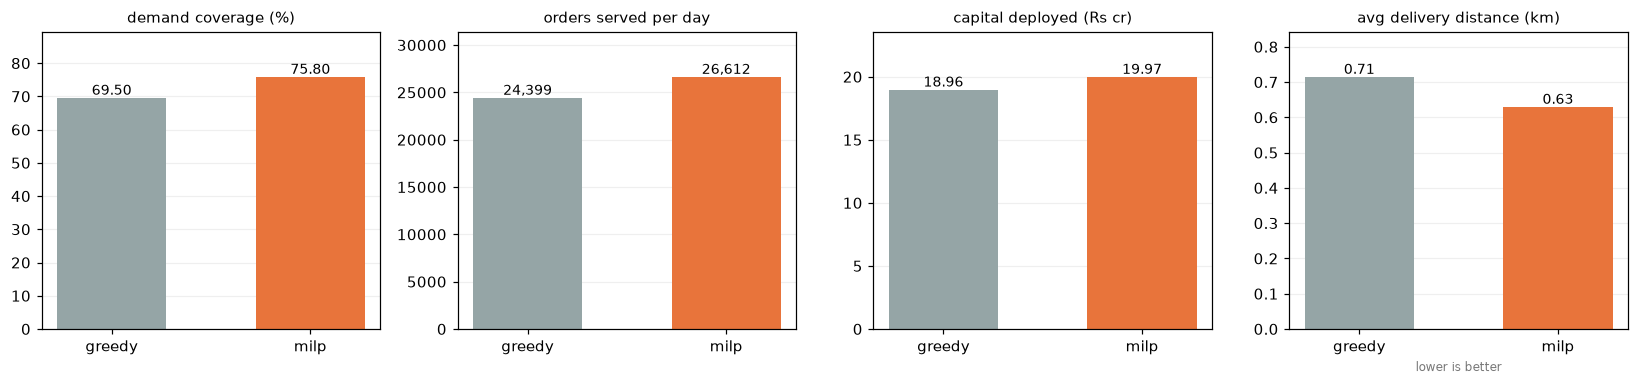

In [14]:
fig = plots.plot_comparison(comparison)
plt.show()

**The mechanism matters more than the number.** Both networks run at 100% capacity utilisation, so
coverage is decided entirely by how much throughput the budget buys. Greedy optimised throughput per
*store*; the optimizer optimised throughput per *rupee*, and bought more, cheaper stores with the same
money. Greedy could not have found this, because answering "which combination of sites buys the most
capacity" requires evaluating combinations, and greedy evaluates one site at a time by construction.

Average delivery distance improves as a side effect — more stores means shorter trips — rather than
because the model was pushed toward it.

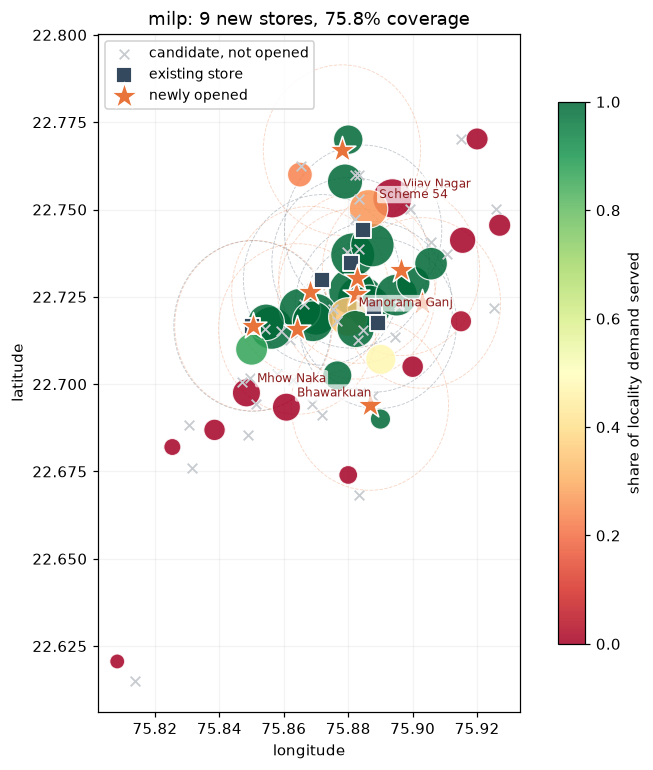

In [15]:
ax = plots.plot_network(optimal, radius_km=RADIUS_KM)
plt.show()

Green localities are fully served, red ones are not. The unserved demand sits in a handful of pockets,
and it is worth being precise about why: the network buys about 26,600 orders/day of capacity against
35,100 of demand, so **roughly 8,500 orders/day cannot be served at any placement** under this budget.
The model is not failing to reach them — it is choosing which demand to walk away from.

Vijay Nagar is the clearest case. It can reach 13 facilities, four of which are open, but every one of
them is saturated serving localities that are *closer*. Given fungible capacity and a distance penalty,
the model concentrates service where it is cheapest to deliver.

That is a defensible optimum and an uncomfortable recommendation, which is worth saying out loud. A real
operator might reasonably prefer partial service everywhere to zero service in three localities, on brand
or competitive grounds the objective function knows nothing about. That preference is expressible — a
minimum-coverage-per-locality constraint — and it would cost total coverage. The model makes the
trade-off visible rather than making it for you.

In [16]:
optimal.unserved_by_locality().head(8)

,locality_id,locality_name,demand,served,unserved,coverage_pct
0,21,Vijay Nagar,1393.1,0.0,1393.1,0.0
1,22,Scheme 54,1336.7,351.4,985.3,26.3
2,9,Manorama Ganj,1350.0,465.7,884.3,34.5
3,28,Mhow Naka,673.3,0.0,673.3,0.0
4,29,Bhawarkuan,671.8,0.0,671.8,0.0
5,17,Bengali Square,582.6,0.0,582.6,0.0
6,13,Tilak Nagar,789.4,375.4,414.0,47.6
7,19,Bicholi Mardana,388.4,0.0,388.4,0.0


---

## How much does λ₁ matter?

λ₁ is a judgment call, not a fact. There is no correct value for how many orders per day one crore of
capital is worth, so the honest response is not to defend a number but to show how far the recommendation
survives moving it.

There is a natural reference point. A store costing ₹2.5 crore and serving ~1,800 orders/day implies a
break-even around **720 orders per crore** — below that, capital is cheap enough to deploy; above it, it
is not.

In [17]:
sweep = sensitivity_sweep(localities, facilities, distances, mask, demand, BUDGET,
                          lambda_values=[0, 100, 200, 300, 400, 500, 600, 700, 720, 800, 900, 1000, 1200])
sweep[["new_stores", "capex_cr", "demand_served", "coverage_pct", "avg_delivery_km"]]

,new_stores,capex_cr,demand_served,coverage_pct,avg_delivery_km
lambda_capex,,,,,
0,9,19.97,26612.0,75.8,0.629
100,9,19.97,26612.0,75.8,0.629
200,9,19.97,26612.0,75.8,0.629
300,9,19.97,26612.0,75.8,0.629
400,9,19.97,26612.0,75.8,0.629
500,9,19.97,26612.0,75.8,0.629
600,9,19.97,26612.0,75.8,0.629
700,9,19.97,26612.0,75.8,0.629
720,8,18.45,25426.0,72.4,0.575


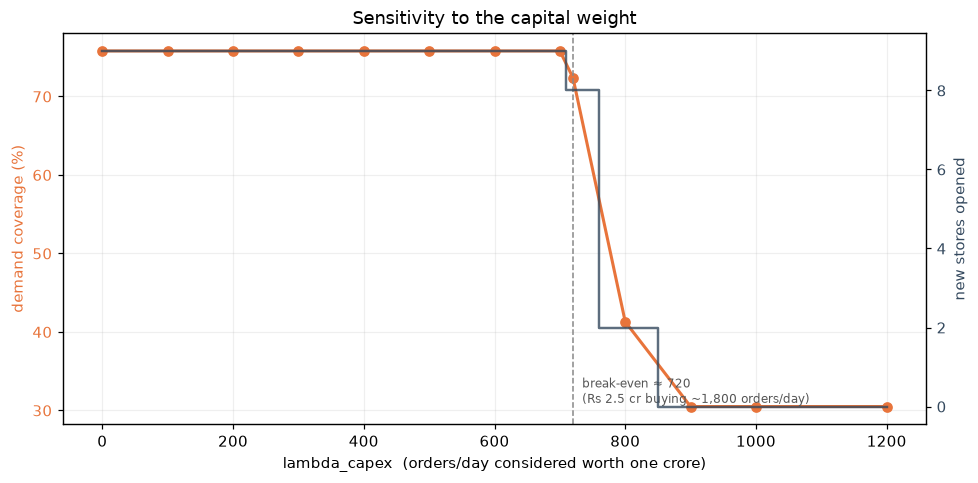

In [18]:
fig = plots.plot_sensitivity(sweep, breakeven=720)
plt.show()

**The plateau is the finding, not the curve.** The recommendation — nine stores, ₹19.97 crore, 75.8%
coverage — is identical for every λ₁ from 0 to 600. It first moves at 720, which is where the analytical
break-even said it should, and capital stops being deployed at all by 900.

So the recommendation does not depend on a parameter nobody can verify. That is what makes it worth
acting on. Had the answer flipped every time λ₁ moved, the right conclusion would have been that the
model was reporting the weight rather than the data.

---

## What does the integrality cost?

Branch-and-bound works by repeatedly solving the **LP relaxation** — the same problem with the binaries
allowed to take fractional values — because that solves fast and its objective bounds any integer
solution from above. The solver then branches on a fractional variable and prunes any subtree whose bound
is already worse than the best integer solution found.

The gap between the two is the price of indivisibility: how much value is lost because stores must be
opened whole.

In [19]:
gap = relaxation_gap(localities, facilities, distances, mask, demand, BUDGET)
print(f"integer optimum  : {gap['integer_objective']:,.1f}")
print(f"LP relaxation    : {gap['relaxed_objective']:,.1f}")
print(f"gap              : {gap['gap_pct']:.3f}%")
print(f"coverage, int/LP : {gap['integer_coverage_pct']:.1f}% / {gap['relaxed_coverage_pct']:.1f}%")

integer optimum  : 21,781.0
LP relaxation    : 21,885.5
gap              : 0.478%
coverage, int/LP : 75.8% / 75.8%


The gap is well under one percent, and that is worth reporting plainly rather than glossing over: on this
instance the combinatorial structure is nearly free, and rounding the relaxation would have landed close
to the integer optimum.

It does not follow that the MILP was unnecessary. The relaxation is not a *plan* — it opens fractions of
stores — and the gap is a property of this instance, not a guarantee. A tighter budget relative to site
costs, where indivisibility bites harder, would widen it. But claiming the integer formulation bought more
than it did would be the kind of overstatement that an interviewer is right to probe.

---

## Festive load

Blinkit has publicly described the capacity strain it faces around Diwali, and the generated data
reproduces it — the festive peak here reaches about 2.5× the median day. So the same model, same budget,
same constraints, re-pointed at scaled demand.

In [20]:
scenarios = scenario_analysis(localities, facilities, distances, mask, demand, BUDGET)
scenarios.drop(columns=["sites"])

,total_demand,new_stores,capex_cr,demand_served,unserved,coverage_pct,avg_delivery_km,capacity_util_pct
multiplier,,,,,,,,
1.0,35120,9,19.97,26612.0,8508,75.8,0.629,100.0
1.5,52681,9,19.98,26571.0,26110,50.4,0.528,100.0
2.0,70241,9,19.98,26571.0,43670,37.8,0.492,100.0
2.5,87801,9,19.98,26571.0,61230,30.3,0.471,100.0


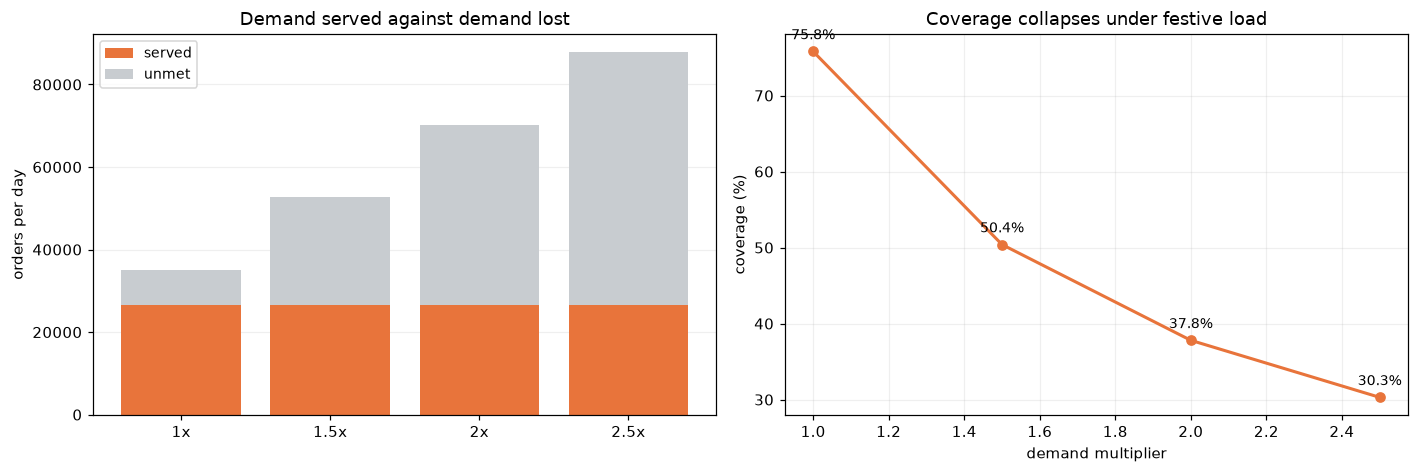

In [21]:
fig = plots.plot_scenarios(scenarios)
plt.show()

Demand served **stops moving**. Same nine stores, same ₹20 crore, at every multiplier — because capacity
is bought with capital and capital is fixed. The binding constraint flips from budget to capacity the
moment demand rises, and coverage falls from 75.8% to 30.3% while the plan itself does not change.

The operational reading: **you cannot buy your way out of a festive peak with a budget sized for a normal
week.** Meeting Diwali demand with permanent capacity would mean carrying ~2.5× the stores year-round for
a week of use — which is why the real answer in quick commerce is temporary capacity, dark-store overflow
space and surge staffing rather than permanent footprint.

One subtlety worth catching: average delivery distance *falls* as demand rises, from 0.629 km to 0.471 km.
That is not an improvement. Saturated stores fill from their nearest localities first, so the demand that
goes unserved is disproportionately the distant demand. The network looks better on that metric precisely
because it is failing more customers — a good reminder that a metric improving is not the same as the
business improving.

---

## Does forecasting demand change the answer?

Everything above sites stores against demand *observed* over the last 90 days, which quietly assumes the
future resembles the past. This section replaces that assumption with a model — and then checks whether
it mattered.

Ridge regression on interpretable features: day-of-week dummies, log population density, income tier, and
lagged demand. The lag is computed strictly from prior days; using same-day demand would be leakage, and
would produce an accuracy figure that could never be reproduced in practice. The split is chronological
rather than random, for the same reason.

And it is benchmarked against **seasonal-naive** — predict each day as the locality's trailing weekly
mean. A forecast without a benchmark has the same problem as an optimizer without one.

In [22]:
from src.forecast import fit_forecast, forecast_demand_vector

raw_demand = pd.read_sql("SELECT * FROM demand", engine)
raw_localities = pd.read_sql("SELECT * FROM localities", engine)

fit = fit_forecast(raw_demand, raw_localities)
print(f"train / test      : {fit['train_days']} days / {fit['test_days']} days")
print(f"ridge MAE         : {fit['ridge_mae']:.1f} orders/day")
print(f"seasonal-naive MAE: {fit['naive_mae']:.1f} orders/day")
print(f"improvement       : {fit['improvement_pct']:.1f}%")
print()
print("largest standardised coefficients:")
print(fit["coefficients"].head(6).round(1).to_string())

train / test      : 69 days / 14 days
ridge MAE         : 62.0 orders/day
seasonal-naive MAE: 85.1 orders/day
improvement       : 27.1%

largest standardised coefficients:
lag_1d    608.2
dow_5     147.6
dow_4     134.8
dow_3     101.3
dow_2      91.5
dow_1      82.4


In [23]:
forecast = forecast_demand_vector(fit, localities)
forecast_demand = forecast["forecast_orders_per_day"].to_numpy(dtype=float)

optimal_forecast = optimize_network(localities, facilities, distances, mask,
                                    forecast_demand, budget=BUDGET)

historical_sites = set(optimal.opened_sites()["facility_key"])
forecast_sites = set(optimal_forecast.opened_sites()["facility_key"])

print(f"demand, historical : {demand.sum():,.0f} orders/day")
print(f"demand, forecast   : {forecast_demand.sum():,.0f} orders/day")
print()
print(f"sites on historical: {len(historical_sites)}  {sorted(historical_sites)}")
print(f"sites on forecast  : {len(forecast_sites)}  {sorted(forecast_sites)}")
print(f"overlap            : {len(historical_sites & forecast_sites)} of {len(historical_sites)}")

demand, historical : 35,120 orders/day
demand, forecast   : 33,784 orders/day

sites on historical: 9  ['S1', 'S12', 'S14', 'S20', 'S23', 'S38', 'S44', 'S5', 'S8']
sites on forecast  : 9  ['S1', 'S12', 'S14', 'S20', 'S23', 'S38', 'S44', 'S5', 'S8']
overlap            : 9 of 9


**The forecast is 27% more accurate than the naive benchmark and changes the siting decision not at all.**
Identical nine sites.

That is a negative result, and it is more useful than a positive one would have been. It says the
recommendation is robust to how well you predict demand — the decision is not bottlenecked on forecasting
accuracy, so effort spent improving the forecast would not have moved it. The reason is structural:
siting depends on the *relative* ranking of localities and on which sites are cheap per unit of capacity,
and a forecast that improves every locality's estimate proportionally leaves both largely unchanged.

Reporting this honestly is worth more than quietly dropping the section or implying it mattered.

---

## Limitations

The method is the contribution here. The numbers are illustrative, and several things would have to be
true before any of this became an operational recommendation.

**The data is synthetic.** No real order volumes, rents, store locations or dispatch times were used, and
none are public at this granularity. Demand is calibrated so that aggregates land near disclosed figures,
but the locality-level variation is invented. Every conclusion is a statement about the method applied to
plausible data, not about Indore.

**Distances are centroid-to-store, and understate reality.** Each locality is collapsed to a single point,
so the model reports ~0.63 km average delivery against a disclosed peer average of ~1.7–1.8 km. Real
distance includes travel within the locality and follows roads rather than great circles. A road-network
distance matrix would raise every distance and shrink the feasible set — probably meaningfully.

**Capacity is a single daily number.** Real stores have hourly peaks, and a store comfortable with 1,800
orders spread across a day may fail badly at the 7pm concentration. Daily capacity flatters the network.

**λ₁ and λ₂ are judgment calls.** The sensitivity analysis shows the recommendation is stable for λ₁ from
0 to 600, which is reassuring, but the weights encode a preference about capital versus coverage that
properly belongs to a finance team, not to an analyst.

**Cannibalisation is modelled only through capacity.** Opening a store near an existing one shifts demand
between them but does not reduce total demand — no substitution effect, no competitive response from
Zepto or Instamart, which in a real market would be the first-order consequence of a visible expansion.

**Spoilage is excluded.** Inventory loss runs ~1.8% of NOV and management has described it as "fairly
asymptotic", meaning hard to improve. It is a real cost of operating each store and would tighten the
economics of marginal sites, but it does not vary enough between sites to change their ranking, which is
why it is left out rather than guessed at.

**The equity trade-off is unaddressed.** The optimum leaves three localities with zero service rather than
spreading partial service. That is optimal against this objective and may well be wrong against the
business's actual preferences. A minimum-coverage constraint would express the alternative, at a cost in
total coverage.

---

## Summary

Framed as a capacitated facility location problem and solved as a MILP, the optimizer opened **9 stores
for ₹19.97 crore and served 75.8% of demand**, against a well-specified greedy baseline's **6 stores,
₹18.96 crore and 69.5%** — about **2,200 additional orders per day for the same capital**, achieved by
buying more, cheaper capacity rather than the individually-largest sites. The recommendation is unchanged
across capital weights from 0 to 600 orders per crore, and unchanged again when demand is replaced with a
model forecast that is 27% more accurate than a naive benchmark.

Under festive load the picture inverts: with capacity fixed by the budget, coverage falls to 30% at 2.5×
demand and no reallocation of the same capital helps — which is an argument for temporary capacity rather
than permanent footprint.